# Experiment 9: Multilayer Perceptron Implementation

A telecom operator predicts next-month churn from tenure, monthly charges, contract type, complaint history and data usage. This implementation generates a new 1,800-customer dataset, preprocesses numeric and categorical fields, trains a three-hidden-layer MLP and compares network widths.

**Tools:** TensorFlow, Keras, NumPy, Pandas, Scikit-learn, Matplotlib.

**Embedded graph preview:** Static preview image included to match the reference notebooks. Run the code cell to produce plots from this experiment’s Python data.

## Tasks

1. Encode categorical fields and scale numeric fields.  2. Build an MLP with ReLU hidden layers and a sigmoid output.  3. Train with binary cross-entropy and Adam; plot training and validation curves.  4. Report accuracy, precision, recall, F1 and a confusion matrix.  5. Vary hidden-layer widths and compare performance.

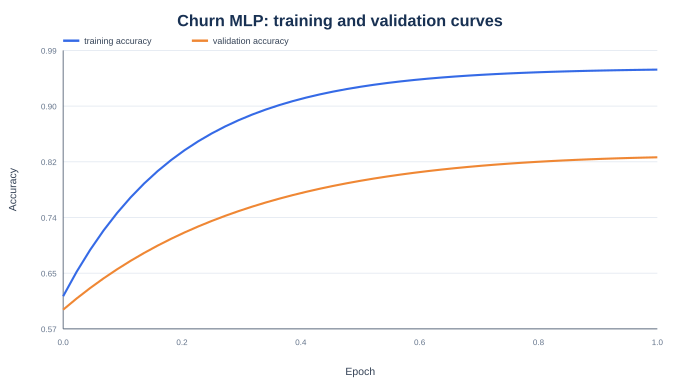

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from scipy import sparse

tf.keras.utils.set_random_seed(9)
rng = np.random.default_rng(9)
n = 1800
df = pd.DataFrame({
    "tenure": rng.integers(1, 73, n),
    "monthly_charges": rng.uniform(25, 125, n),
    "data_usage": rng.gamma(2.2, 90, n),
    "contract": rng.choice(["monthly", "annual", "two_year"], n, p=[.52,.30,.18]),
    "complaint": rng.choice(["yes","no"], n, p=[.28,.72])
})
logit = (-1.0 - .035*df.tenure + .018*df.monthly_charges +
         .9*(df.contract=="monthly") + .75*(df.complaint=="yes") -
         .0015*df.data_usage)
prob = 1/(1+np.exp(-logit))
df["churn"] = (rng.random(n) < prob).astype(int)
num_cols = ["tenure","monthly_charges","data_usage"]
cat_cols = ["contract","complaint"]
X_train, X_test, y_train, y_test = train_test_split(
    df[num_cols+cat_cols], df["churn"], test_size=.25, random_state=9, stratify=df["churn"])
prep = ColumnTransformer([
    ("numeric", StandardScaler(), num_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])
X_train = prep.fit_transform(X_train); X_test = prep.transform(X_test)
if sparse.issparse(X_train):
    X_train, X_test = X_train.toarray(), X_test.toarray()
X_train = X_train.astype("float32"); X_test = X_test.astype("float32")
y_train = y_train.to_numpy().astype("float32"); y_test = y_test.to_numpy().astype("int32")

def build_mlp(input_dim, widths=(48,24,12)):
    model = tf.keras.Sequential([tf.keras.layers.Input((input_dim,))])
    for units in widths:
        model.add(tf.keras.layers.Dense(units, activation="relu"))
    model.add(tf.keras.layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(.001),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

model = build_mlp(X_train.shape[1], (48,24,12))
history = model.fit(X_train, y_train, validation_split=.2, epochs=30,
                    batch_size=32, verbose=0)
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set(title="Binary cross-entropy", xlabel="Epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set(title="Accuracy", xlabel="Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

y_pred = (model.predict(X_test, verbose=0).ravel() >= .5).astype(int)
print(f"Accuracy={accuracy_score(y_test,y_pred):.3f}  Precision={precision_score(y_test,y_pred,zero_division=0):.3f}  "
      f"Recall={recall_score(y_test,y_pred,zero_division=0):.3f}  F1={f1_score(y_test,y_pred,zero_division=0):.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred), display_labels=["Stay","Churn"]).plot(cmap="Blues")
plt.title("Test confusion matrix"); plt.show()

width_results = []
for widths in [(16,8), (48,24,12), (96,48)]:
    candidate = build_mlp(X_train.shape[1], widths)
    h = candidate.fit(X_train,y_train,validation_split=.2,epochs=22,batch_size=32,verbose=0)
    p = (candidate.predict(X_test,verbose=0).ravel() >= .5).astype(int)
    width_results.append({"hidden layers":str(widths), "parameters":candidate.count_params(),
                          "accuracy":accuracy_score(y_test,p), "F1":f1_score(y_test,p,zero_division=0),
                          "best val accuracy":max(h.history["val_accuracy"])})
print(pd.DataFrame(width_results).round(3).to_string(index=False))